# Correlation Table of speed vs Vehicles data

In [7]:
import numpy as np
import pandas as pd
from pandas import DataFrame, concat
import os,itertools
from datetime import datetime
import calendar

In [8]:
ROUTE_LIST = ['b_PIE', 'b_Woodlands']
read_df = pd.read_csv('output_test_septem_v1 - Copy.csv')
wood_df  = read_df.loc[(read_df['Route']==ROUTE_LIST[1])]
pie_df  = read_df.loc[(read_df['Route']==ROUTE_LIST[0])]

In [9]:
def get_correlation(df, Route):
    pdf = pd.DataFrame(columns=df["X5_Day_name"].unique().tolist())
    
    month_list = df["X14_Month"].unique().tolist()
    
    for i in range(len(month_list)):
        
        #compute correlation of every month
        for day in df["X5_Day_name"].unique().tolist():
            
            #Compute the correlation matrix
            temp_df = df.loc[df['X14_Month'].eq(month_list[i]) & df['X5_Day_name'].eq(day)][['X1_Vehicles_no_filter','Y_Speed']].corr()
            
            ## Fill the day with corresponding correlation 
            pdf.at[i, day]=temp_df.at['X1_Vehicles_no_filter', 'Y_Speed']
        
        ## fill the month column
        pdf.loc[i, ['Month']] =  month_list[i]
        pdf.loc[i, ['Route']] = Route
    
    return pdf
wood_corr = get_correlation(wood_df, ROUTE_LIST[1])
pie_corr = get_correlation(pie_df, ROUTE_LIST[0])
final_df =  [wood_corr,pie_corr]
result = pd.concat(final_df)

# Assume 'Month' is the column containing the month number in your DataFrame
result['Month'] = result['Month'].astype(int)  # Convert column to integers
result['Month'] = result['Month'].apply(lambda x: calendar.month_name[x])

#Rearrange the column order
column_order = ['Route', 'Monday'] + [col for col in result.columns if col not in ['Route', 'Monday']]
result = result.reindex(columns=column_order)

result.to_csv("1.correlation_speed_Vs_total vehicles.csv",index=False)
result

,Route,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday,Month
0,b_Woodlands,-0.53283,-0.52503,-0.54822,-0.519041,-0.527211,-0.323706,-0.238663,March
1,b_Woodlands,-0.534513,-0.586709,-0.583114,-0.550103,-0.17837,-0.269399,-0.207988,April
2,b_Woodlands,-0.492659,-0.640719,-0.453376,-0.522509,-0.565553,-0.086677,-0.103536,May
3,b_Woodlands,-0.434961,-0.468455,-0.518112,-0.529124,-0.535957,-0.209663,-0.175683,June
0,b_PIE,-0.63171,-0.588155,-0.60845,-0.592514,-0.57632,-0.386262,-0.278638,March
1,b_PIE,-0.649108,-0.637812,-0.628834,-0.542009,-0.060374,-0.4355,-0.078004,April
2,b_PIE,-0.637062,-0.623595,-0.661099,-0.629801,-0.586362,-0.326314,-0.404112,May
3,b_PIE,-0.60511,-0.612363,-0.655619,-0.661676,-0.62917,-0.414599,-0.159248,June


# Compute error score for report

In [20]:
june_wl  =  pd.read_csv(os.path.join('b_Woodlands_best_models', "b_Woodlands_june_speed_result.csv"))
june_wl.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,rf_m2,rf_m1,rf_m3,rf_m4,xgb_m2_1,lstm_m2_1,xgb_m2_3,lstm_m2_3,xgb_m2_6,lstm_m2_6
0,2022-06-20 05:00:00,b_Woodlands,6,2703,81,80,79,82,82,78,...,79,80,82,82,78.0,82.0,77.0,80.0,78.0,80.0
1,2022-06-20 05:05:00,b_Woodlands,6,2703,81,80,79,81,81,78,...,78,80,82,81,78.0,81.0,77.0,80.0,77.0,80.0


In [21]:
june_pie  = pd.read_csv(os.path.join('b_PIE_best_models', "b_PIE_june_speed_result.csv"))
june_pie.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,m2_1_org,lstm_m2_1_diff,xgb_m2_1_diff,m2_3_org,lstm_m2_3_diff,xgb_m2_3_diff,m2_6_org,lstm_m2_6_diff,xgb_m2_6_diff,ROUTE
0,2022-06-20 05:00:00,b_PIE,6,2705,83,81,82,84,84,83,...,89.0,3.0,6.0,89.0,5.0,6.0,83.0,1.0,0.0,b_PIE
1,2022-06-20 05:05:00,b_PIE,6,2705,89,81,82,83,83,83,...,87.0,1.0,4.0,87.0,3.0,4.0,85.0,3.0,2.0,b_PIE


In [22]:
model_list = [
              'lstm_m2', 'xgb_m2', 'svr_m2','rf_m2'
            ]

unique_models = []
unique_Algs = []

for model in model_list:
    # Split the model name into algorithm name and model name using '_' as the separator
    unique_Algs.append(model.split("_", maxsplit=1)[0])
    unique_models.append(model.split("_", maxsplit=1)[1])

## To preserve order
unique_Algs = list(set(unique_Algs))  # Remove duplicate algorithm names while preserving order
unique_models = list(set(unique_models))  # Remove duplicate model names while preserving order

print("Unique Algorithms:")
print(unique_Algs)

print("\nUnique Models:")
print(unique_models)


Unique Algorithms:
['rf', 'xgb', 'lstm', 'svr']

Unique Models:
['m2']


In [23]:
model_list = [
              'lstm_m2', 'xgb_m2', 'svr_m2','rf_m2']

unique_Algs = sorted(set([model.split("_", maxsplit=1)[0] for model in model_list]), key=lambda x: ['lstm', 'xgb', 'svr','rf'].index(x))
unique_models = sorted(set([model.split("_", maxsplit=1)[1] for model in model_list]), key=lambda x: int(x[1:]))

print("Unique Algorithms:")
print(unique_Algs)

print("\nUnique Models:")
print(unique_models)


Unique Algorithms:
['lstm', 'xgb', 'svr', 'rf']

Unique Models:
['m2']


In [24]:
#https://datascienceparichay.com/article/python-split-string-by-underscore/
import numpy as np
from sklearn.metrics import mean_squared_error,explained_variance_score,mean_absolute_error


# Function to calculate error for each algorithm and model
def calculate_error(df, route, error_function):
    pdf = pd.DataFrame(columns=unique_models)
    pdf['Algorithm'] = unique_Algs
    pdf['Route'] = route
    pdf['error'] = error_function
        
    for i in range(len(model_list)):
        name_split = model_list[i].split("_", maxsplit=1)
        Algorithm = name_split[0]   # Extract the algorithm name (e.g., XGB)
        Model = name_split[1]     # Extract the model name (e.g., Wo_CURR_Y_LAG)
        
        # Calculate the error
        if(error_function=='rmse'):
            res = np.sqrt(mean_squared_error(df.Y_Speed, df[model_list[i]]))
        else:
            res = error_function(df.Y_Speed, df[model_list[i]])
        
        # Fill the corresponding column
        pdf.loc[unique_Algs.index(Algorithm), [Model]] = res
    
    # Rearrange the columns
    #pdf2 = pdf[pdf.columns[[5, 4, 0, 1, 2, 3, 6]]]
    
    #Rearrange the column order
    column_order = ['Route', 'Algorithm'] + [col for col in pdf.columns if col not in ['Route', 'Algorithm']]
    pdf = pdf.reindex(columns=column_order)

    return pdf



In [17]:
def calculate_all_errors(df,route):
    mse = calculate_error(df,route, 'rmse')
    mae = calculate_error(df,route, mean_absolute_error)
    exp = calculate_error(df,route, explained_variance_score)
    
    return  mse, mae, exp

mse_pie,mae_pie, exp_e_pie = calculate_all_errors(june_pie,"b_PIE")
mse_wl, mae_wl, exp_e_wl = calculate_all_errors(june_wl,"b_Woodlands")
#mse_2way, mae_2way, exp_e_2way = calculate_all_errors(june_2way,'2way')

In [25]:
def concat_df(frames):
    # Concatenate the frames vertically (along the rows)
    return pd.concat(frames, axis=0, sort=False, ignore_index=True)

# Concatenate the dataframes vertically for MSE
frames = [mse_pie, mse_wl]
mse_result = concat_df(frames)

# Concatenate the dataframes vertically for MAE
frames = [mae_pie, mae_wl]
mae_result = concat_df(frames)

# Concatenate the dataframes vertically for explained variance score
frames = [exp_e_pie, exp_e_wl]
exp_result = concat_df(frames)

# Drop unnecessary columns from MAE result dataframe
mae_result.drop(["Route", "Algorithm"], axis=1, inplace=True)

# Drop unnecessary columns from explained variance score result dataframe
exp_result.drop(["Route", "Algorithm"], axis=1, inplace=True)


In [27]:
combined_output = pd.concat([mse_result, mae_result, exp_result], axis=1)

combined_output.to_csv("3.error_summary.csv",index=False)
combined_output

,Route,Algorithm,m2,error,m2,error,m2,error
0,b_PIE,lstm,5.769009,rmse,3.434575,<function mean_absolute_error at 0x0000013DFB0...,0.71961,<function explained_variance_score at 0x000001...
1,b_PIE,xgb,5.726772,rmse,3.323487,<function mean_absolute_error at 0x0000013DFB0...,0.723059,<function explained_variance_score at 0x000001...
2,b_PIE,svr,6.378206,rmse,4.13938,<function mean_absolute_error at 0x0000013DFB0...,0.660081,<function explained_variance_score at 0x000001...
3,b_PIE,rf,5.679646,rmse,3.31683,<function mean_absolute_error at 0x0000013DFB0...,0.727052,<function explained_variance_score at 0x000001...
4,b_Woodlands,lstm,3.872198,rmse,2.60078,<function mean_absolute_error at 0x0000013DFB0...,0.740915,<function explained_variance_score at 0x000001...
5,b_Woodlands,xgb,3.696817,rmse,2.55507,<function mean_absolute_error at 0x0000013DFB0...,0.746847,<function explained_variance_score at 0x000001...
6,b_Woodlands,svr,4.613536,rmse,3.404524,<function mean_absolute_error at 0x0000013DFB0...,0.631234,<function explained_variance_score at 0x000001...
7,b_Woodlands,rf,4.013083,rmse,2.806864,<function mean_absolute_error at 0x0000013DFB0...,0.698633,<function explained_variance_score at 0x000001...


In [28]:
def generate_hour_vs_speed(df, model_to_plot, route, month):
    # Print a new line for separation
    print()
    
    # Set the figure size
    plt.figure(figsize=(10, 6))
    
    # Set the title of the plot
    title = "Speed of vehicles each hour at " + route + " in the month of " + month
    plt.title(title, fontsize=17)
    
    # Set the figure size using sns.set
    sns.set(rc={'figure.figsize':(11.7, 8.27)})
    
    # Set the color palette for the plot
    palette = sns.color_palette("mako_r", 7)
    
    # Create the line plot
    ax = sns.lineplot(data=df, x=df.hour, y=model_to_plot, hue="X5_Day_name", style="X5_Day_name",
                      markers=True, dashes=False, legend="full", linewidth=6)
    
    # Set the X-axis limits and format
    ax.set(xlim=(5, 23))
    
    # Set the font size for legend texts and title
    plt.setp(ax.get_legend().get_texts(), fontsize='13')  # for legend text
    plt.setp(ax.get_legend().get_title(), fontsize='13')  # for legend title
    
    # Set the x-label and y-label
    plt.xlabel("Hour", fontsize=15)
    plt.ylabel("Speed", fontsize=15)
    
    # Set the font size for x-axis and y-axis tick labels
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    # Show the plot
    plt.show()

    

# plot speed for unseen data

In [29]:
import seaborn as sns
from matplotlib import pyplot as plt, dates as mdates
import warnings

UNSEEN_DATA_FOLDER = "test_data_unseen"

def generate_time_vs_speed(df, model_to_plot, route, month):
    # Create a figure and axis with a specified figsize
    fig, ax = plt.subplots(figsize=(40, 20))
    
    # Create a line plot using sns.lineplot
    ax = sns.lineplot(data=df, x='hh_mm', y=model_to_plot, hue='X5_Day_name', style="X5_Day_name",
                      markers=True, dashes=False, linewidth=7, errorbar=None)
    
    # Set the x-label and y-label
    plt.xlabel(" Hour ", fontsize=50)
    plt.ylabel(" Speed Km/hr ", fontsize=50)
    
    # Adjust the label position to include a space
    plt.gca().xaxis.set_label_coords(0.5, -0.08)  # Adjust the second parameter for vertical spacing
    plt.gca().yaxis.set_label_coords(-0.04, 0.5)  # Adjust the first parameter for horizontal spacing

    # Set the font size for x-axis and y-axis tick labels
    plt.xticks(fontsize=40)
    plt.yticks(fontsize=40)
    
    plt.ylim(40, 90)
    
    # Get the legend handles and set the linewidth for the legend lines
    handles, labels = ax.get_legend_handles_labels()
    for handle in handles:
        handle.set_linewidth(5)  # Set the desired linewidth for the legend lines
    
    # Recreate the legend with the modified handles
    ax.legend(handles, labels, fontsize=40)
    
    # Set the title
    title = f"Speed of vehicles every hour at {route} in the month of {month}"
    #plt.title(title, fontsize=50, pad=20)
    print()
    
    fileName = os.path.join(UNSEEN_DATA_FOLDER, route + "_" + month + "_plot.png")
    print(fileName)
    plt.savefig(fileName, format="png", bbox_inches="tight", dpi=600)
    
    # Show the plot
    plt.show()



def read_and_plot(fileName, model_name, route, month):
    # Read the CSV file into a DataFrame
    read_df = pd.read_csv(os.path.join(UNSEEN_DATA_FOLDER, fileName))
    
    # Filter the DataFrame based on the provided route
    df = read_df.loc[(read_df['Route'] == route)].copy() 
    
    # Convert the 'Timestamp' column to datetime format
    df['Timestamp'] = pd.to_datetime(df['Timestamp'])
    
    # Extract the hour and minute from the 'Timestamp' column
    df['hh_mm'] = df['Timestamp'].dt.strftime('%H')
    
    df = df.loc[(df['hh_mm'] != '04')]
    
    # Call the 'generate_time_vs_speed' function to generate the plot
    generate_time_vs_speed(df, model_name, route, month)

    

## Plot for July


test_data_unseen\b_PIE_july_plot.png


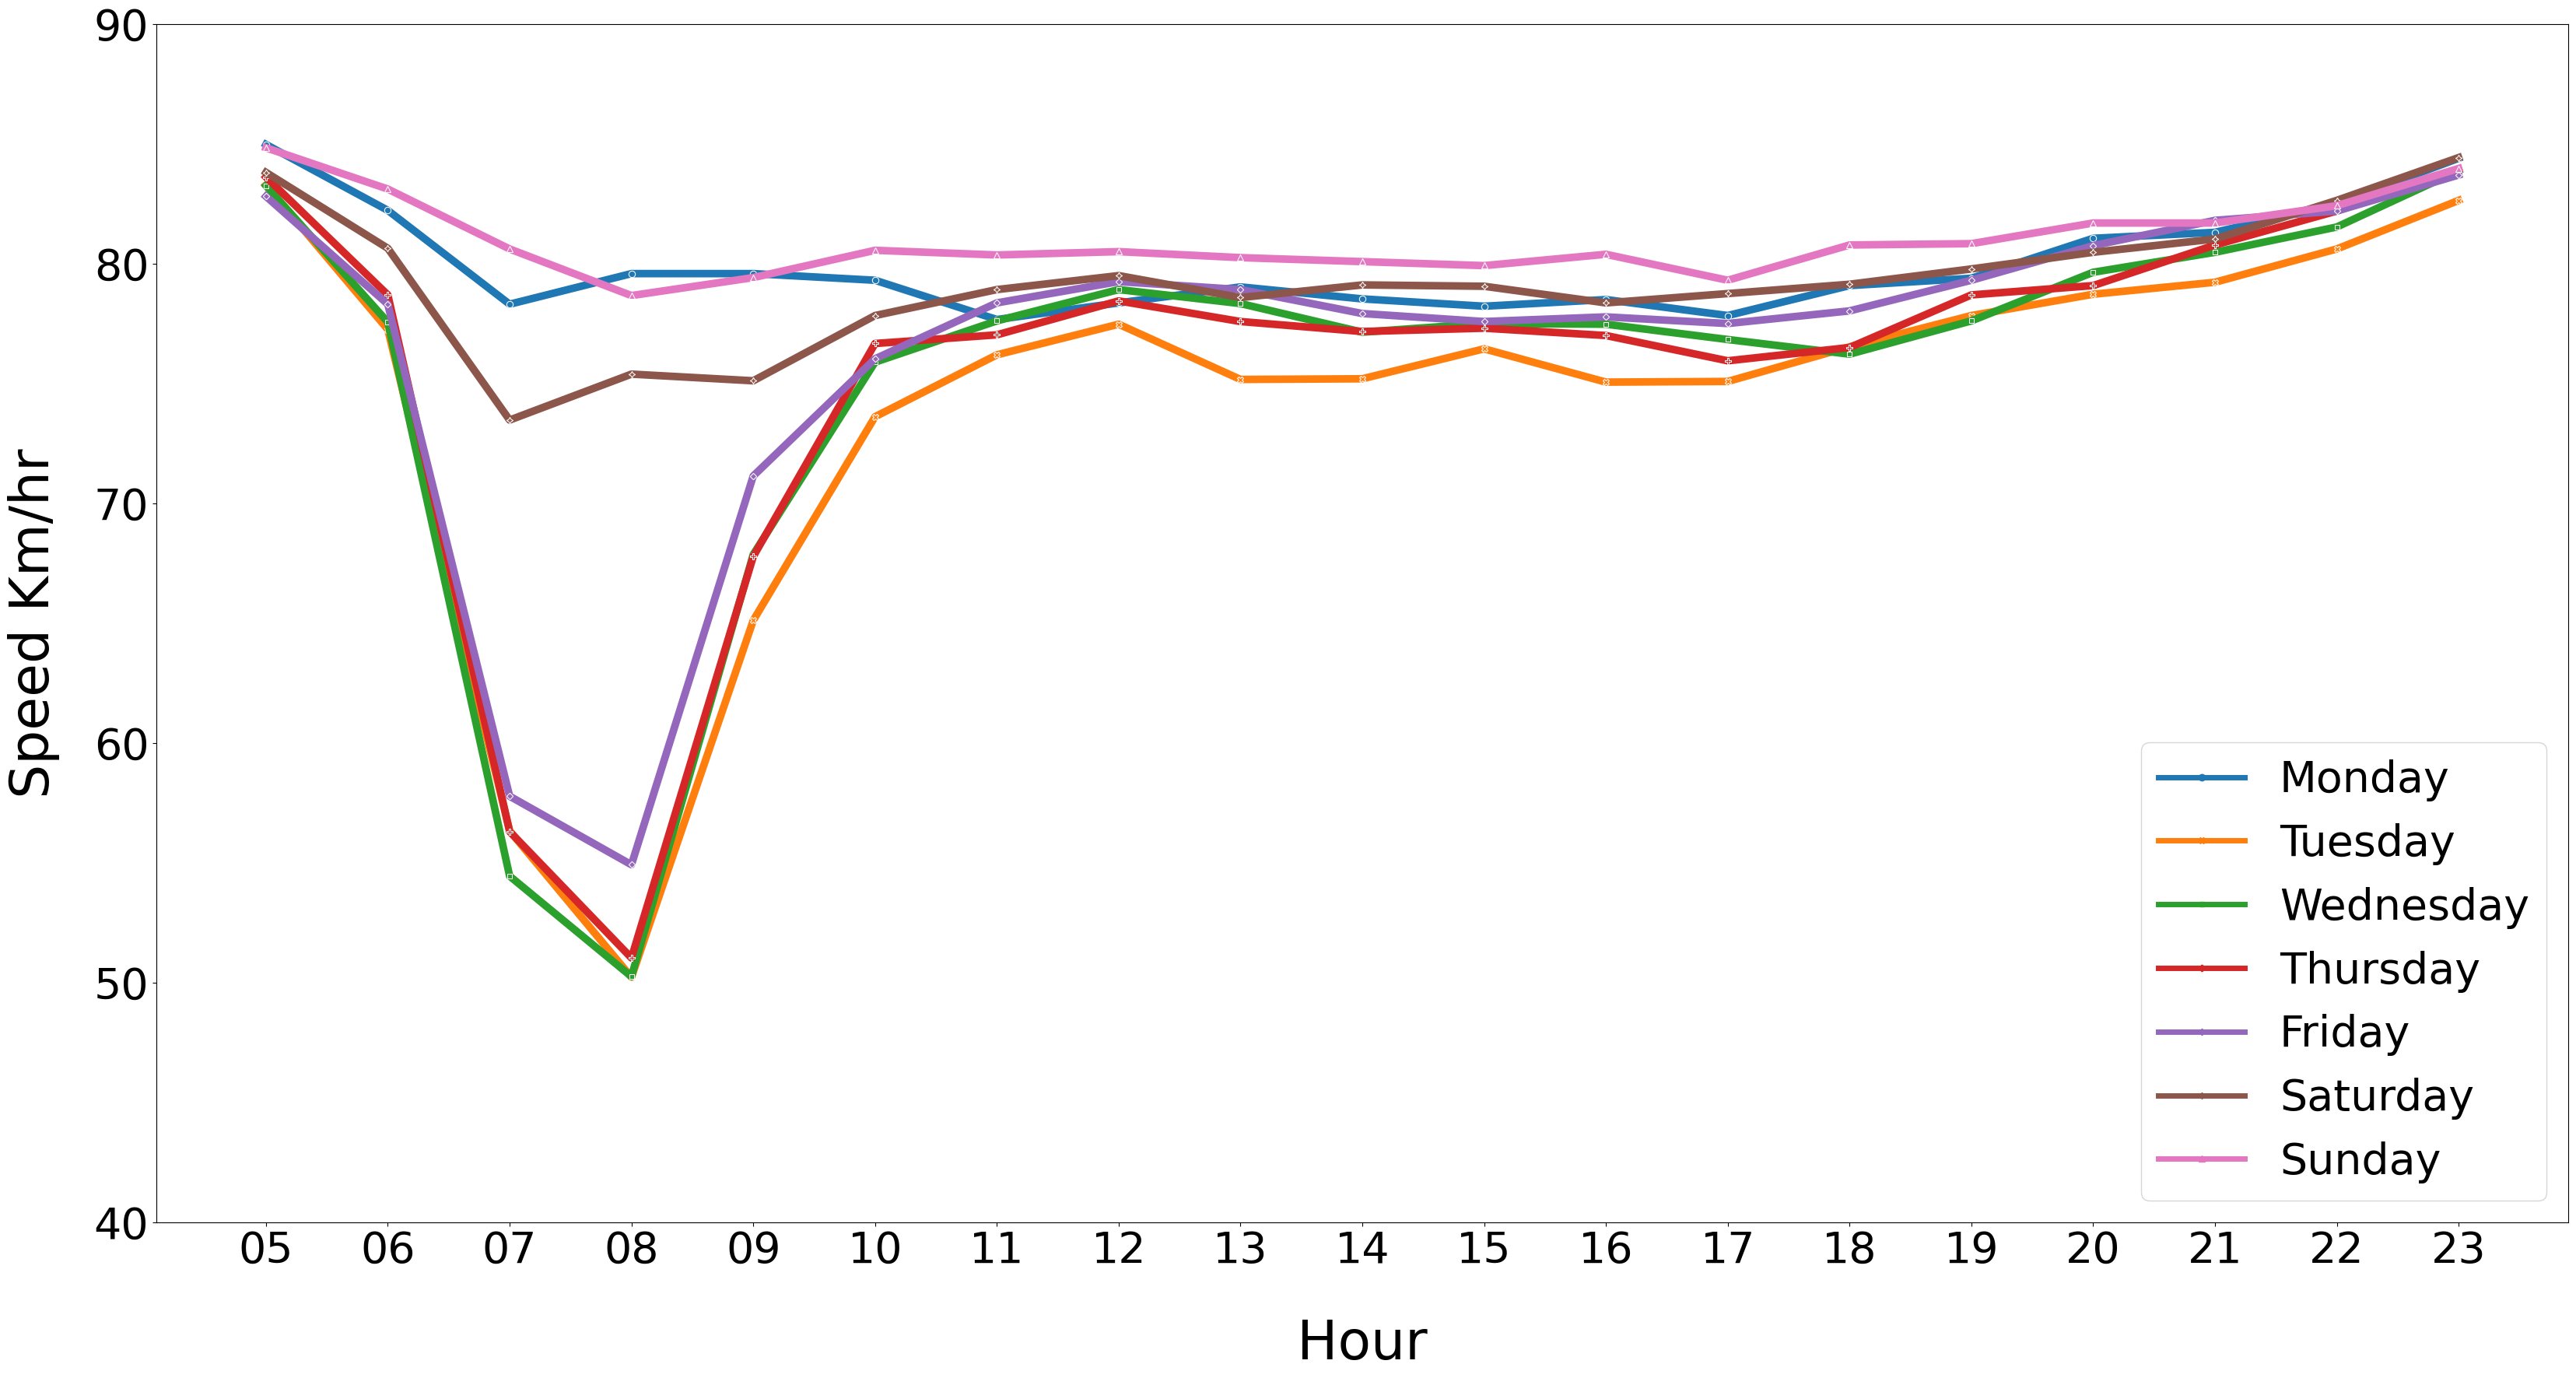

In [30]:
fileName = "jul_full_b_PIE.csv"
model_name = "xgb_m2"
read_and_plot(fileName, model_name, "b_PIE", "july" )

In [ ]:
fileName = "jul_full_b_Woodlands.csv"
model_name = "lstm_m2"
read_and_plot(fileName,model_name, "b_Woodlands", "july"  )

## Plot for February


test_data_unseen\b_PIE_feb_plot.png


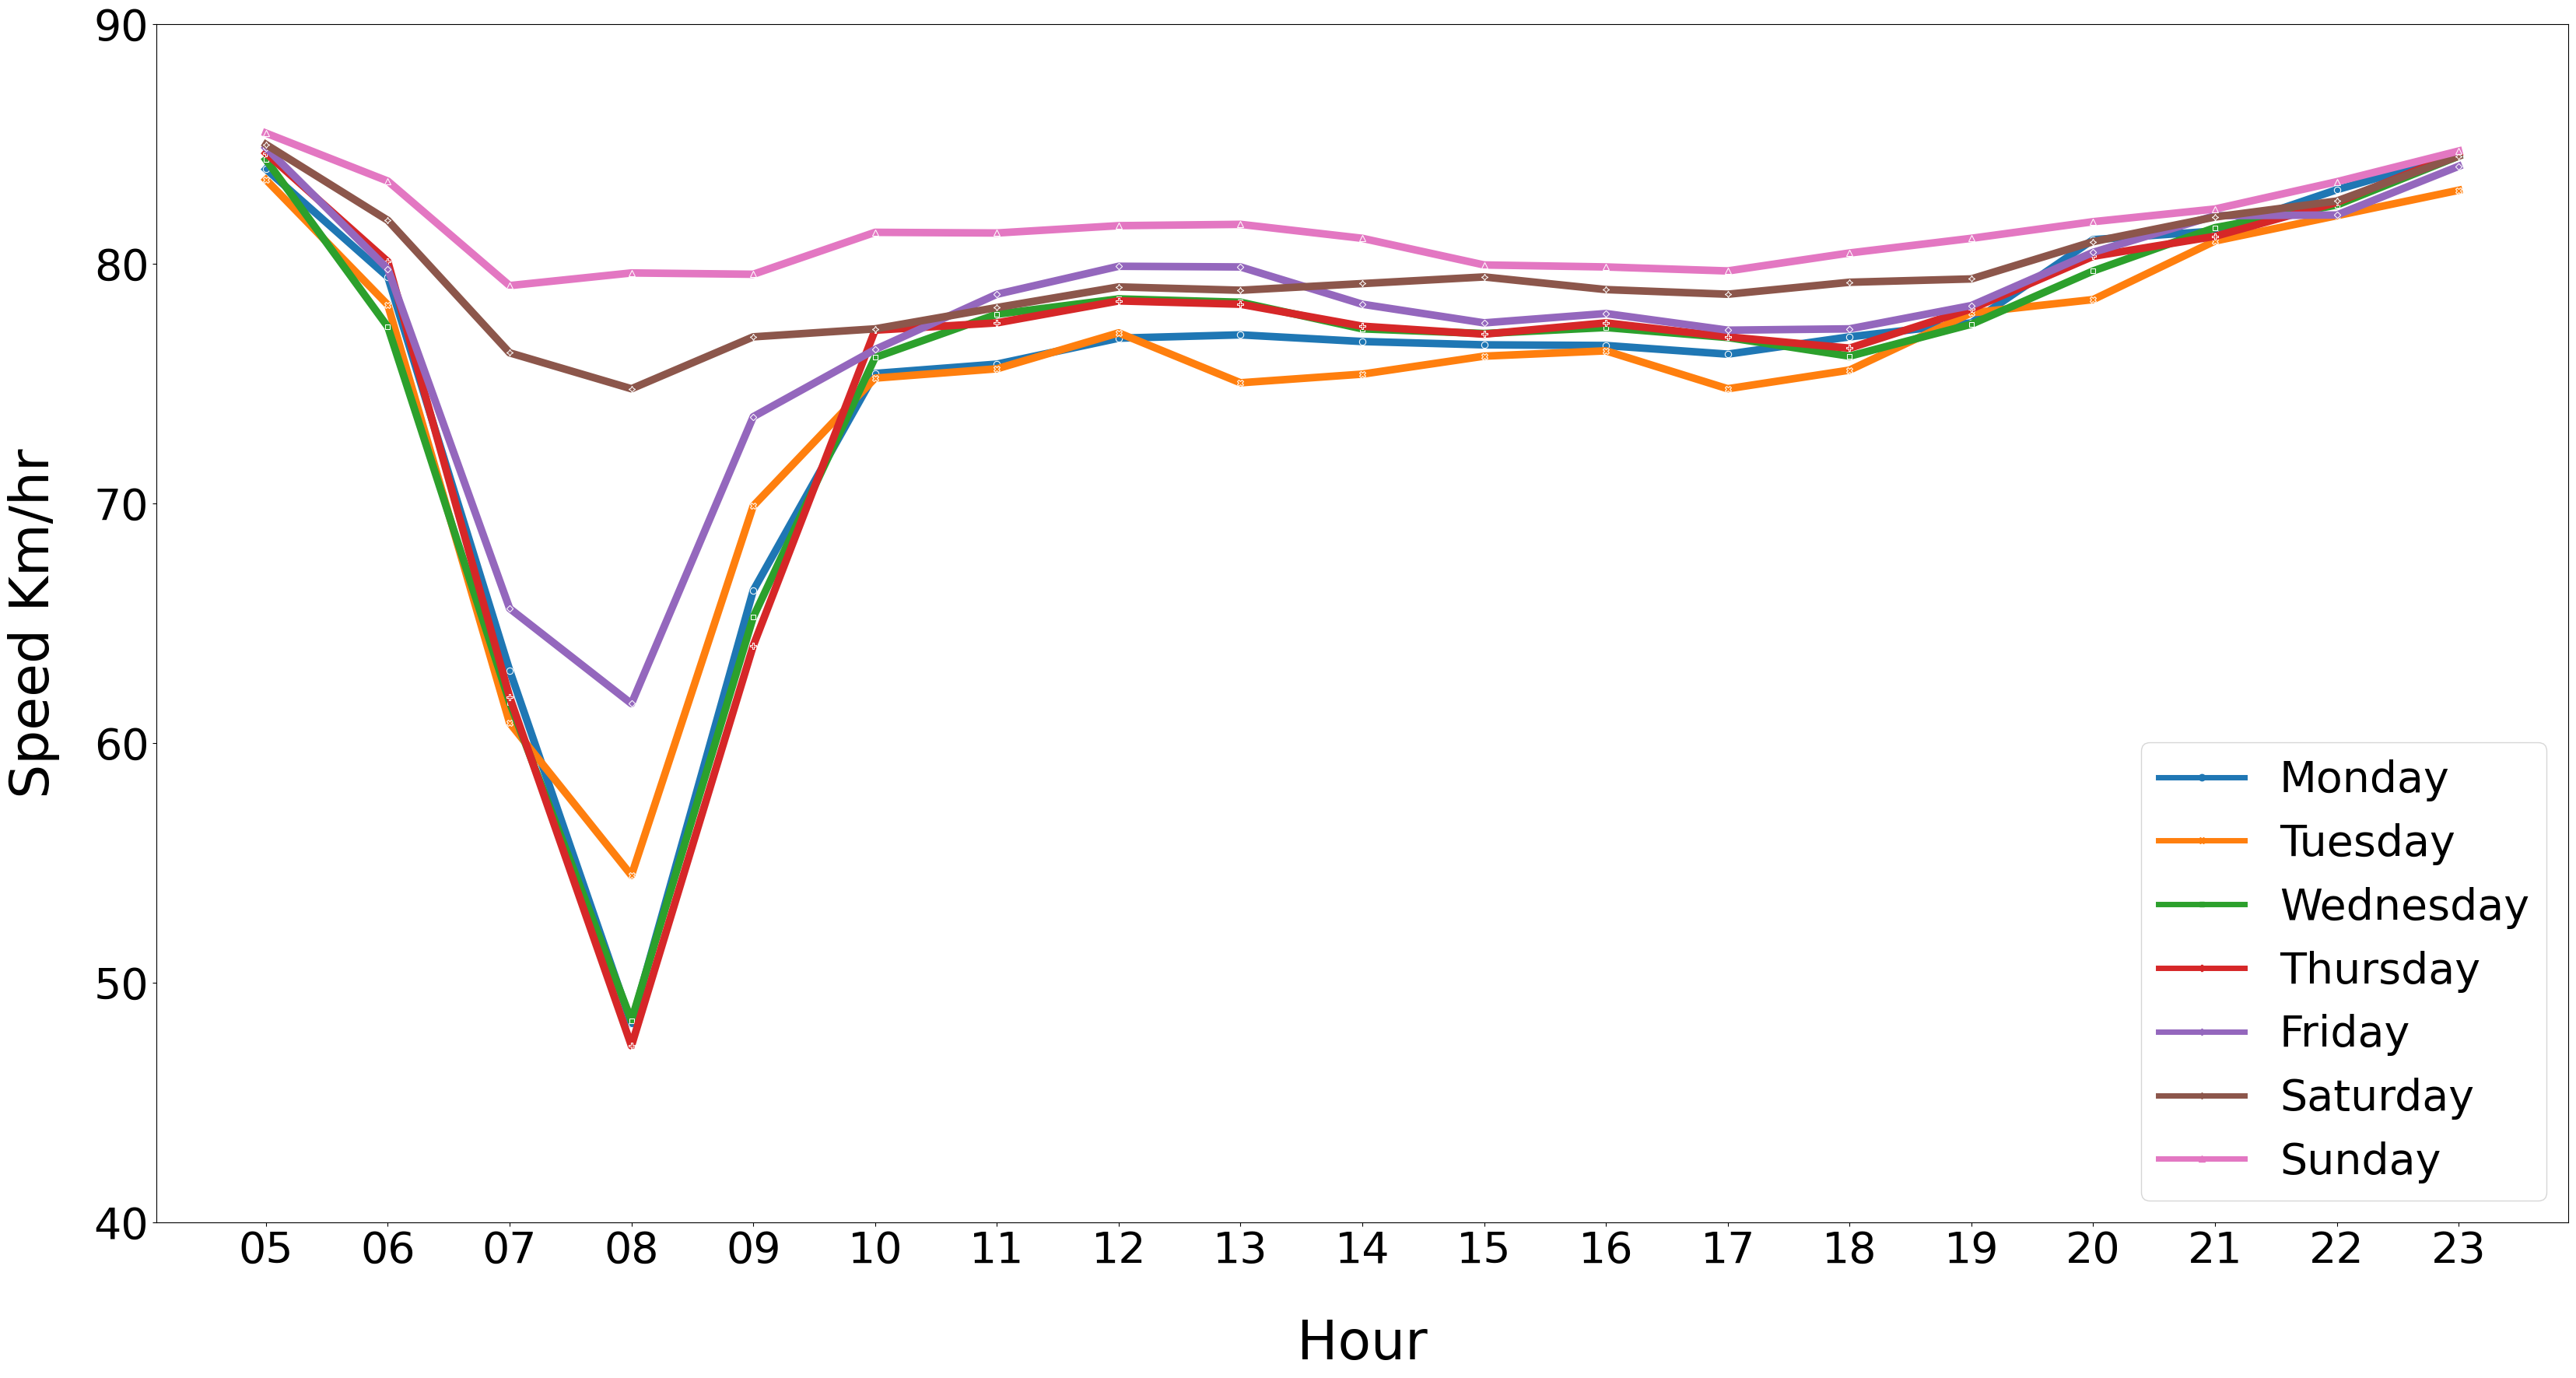

In [17]:
fileName = "feb_full_b_PIE.csv"
model_name = "xgb_m2"
read_and_plot(fileName,model_name,"b_PIE", "feb" )


test_data_unseen\b_Woodlands_feb_plot.png


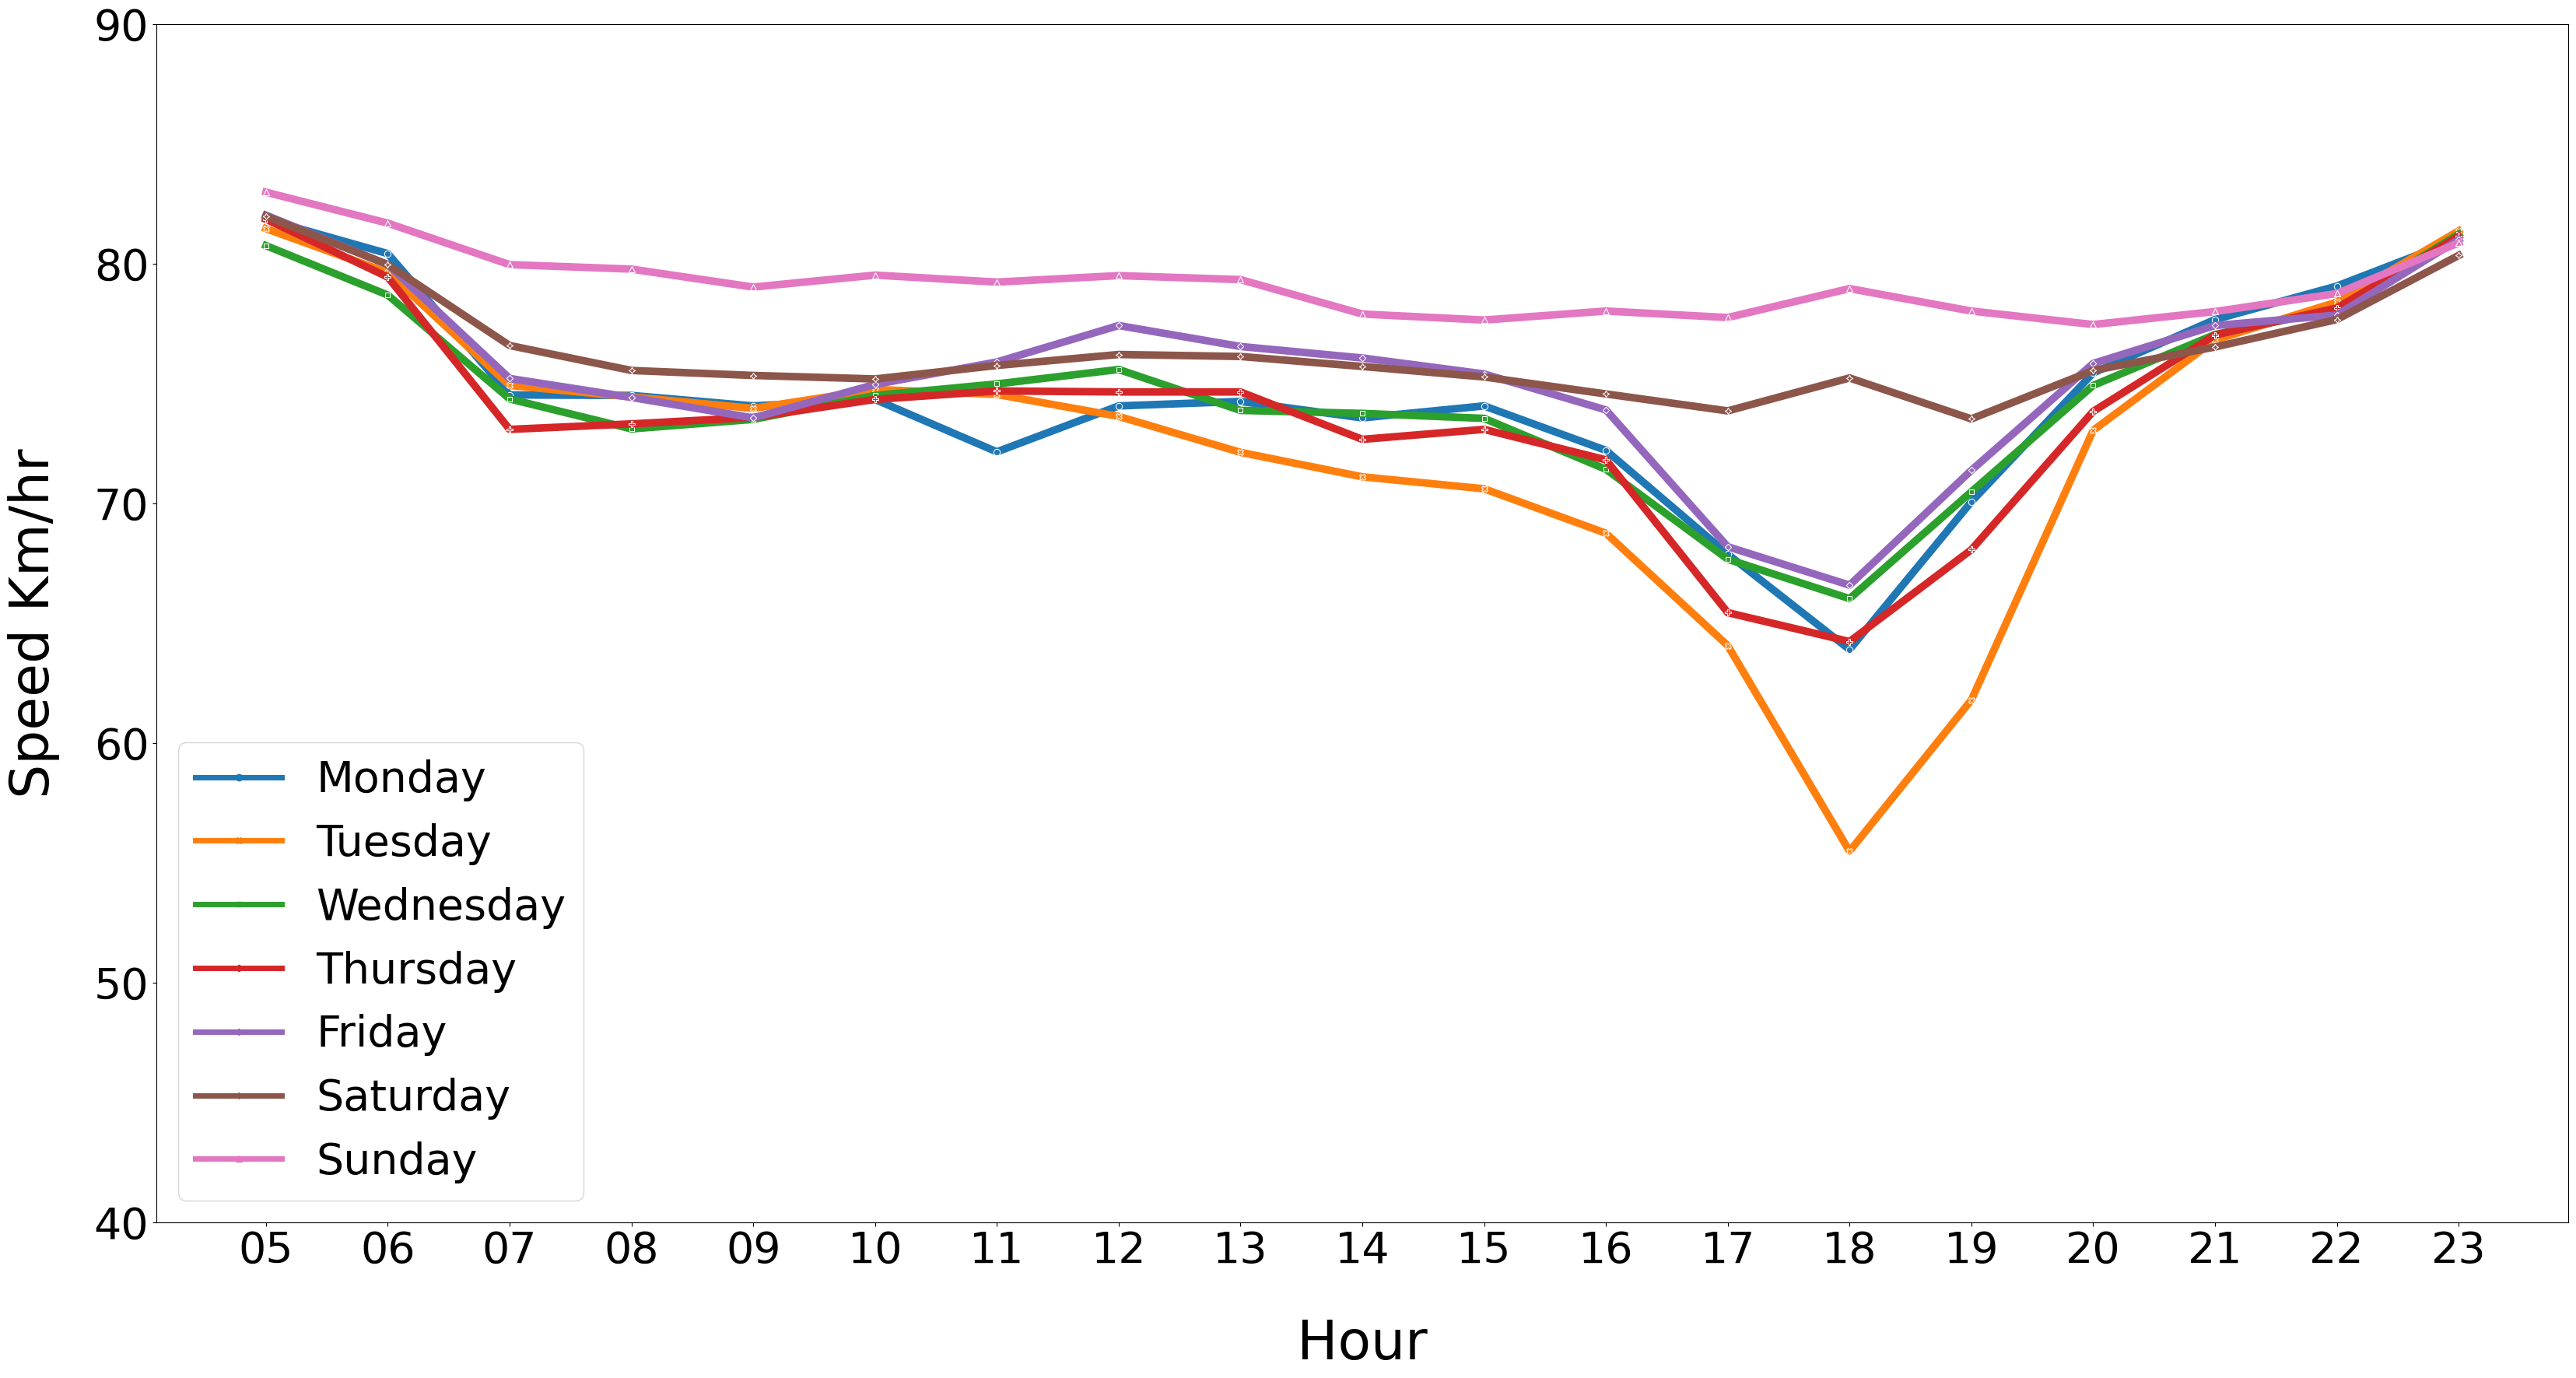

In [18]:
fileName = "feb_full_b_Woodlands.csv"
model_name = "lstm_m2"
read_and_plot(fileName,model_name, "b_Woodlands","feb" )

# Calculation model performance ratio

In [19]:
june_wl  =  pd.read_csv(os.path.join('b_Woodlands_best_models', "b_Woodlands_june_speed_result.csv"))
june_wl.columns

Index(['Timestamp', 'Route', 'X14_Month', 'Camera_id', 'Y_Speed', 'svr_m1',
       'svr_m2', 'svr_m3', 'svr_m4', 'xgb_m1', 'lstm_m1', 'lstm_m2', 'lstm_m3',
       'lstm_m4', 'xgb_m2', 'xgb_m3', 'xgb_m4', 'rf_m2', 'rf_m1', 'rf_m3',
       'rf_m4'],
      dtype='object')

### calculate the difference between the actual speed (Y_Speed) and the predicted speed for each model 

In [20]:
def find_predicted_speed_diff(input_df):
    df = input_df.copy()
    diff_model_names = []  # Initialize an empty list to store the new column names that contains speed diff
    
    for model_name in model_list:
        new_name = "diff_" + model_name  # Create the column name with prefix 'diff_'
        diff_model_names.append(new_name)  # Add the new column name to the list
        
        df[new_name] = df['Y_Speed'] - df[model_name]  # Calculate the difference and assign it to the new column
    
    return df, diff_model_names  # Return the updated DataFrame and the list of new column names

### Find the closest predicted model

In [21]:
from collections import Counter
def find_closest_predicted_model(df_w_speed_diff, diff_model_names):
    
    diff_cols = df_w_speed_diff[diff_model_names]
    
    # Find the absolute differences between values and zero for each row
    abs_diff = np.abs(diff_cols - 0)

    # Find the minimum absolute difference for each row
    min_abs_diff = abs_diff.min(axis=1)

    # Find the column names with the closest absolute difference to zero for each row
    closest_predicted_model = abs_diff.apply(lambda row: list(row[row == min_abs_diff[row.name]].index), axis=1).tolist()
    
    # Extract column names without the 'diff_' prefix
    closest_predicted_model = [[col.replace('diff_', '') for col in cols] for cols in closest_predicted_model]
    
    # Flatten the list of closest columns
    flat_closest_columns = [col for sublist in closest_predicted_model for col in sublist]

    # Count the occurrences of each model
    model_occurance_count = dict(Counter(flat_closest_columns))

    return closest_predicted_model , model_occurance_count


# Call the function to extract speed diff for each model
df_w_speed_diff, diff_model_names = find_predicted_speed_diff(june_wl)

closest_predicted_model, model_occurance_count = find_closest_predicted_model(df_w_speed_diff, diff_model_names)
june_wl['closest_predicted_model'] = closest_predicted_model

In [22]:
june_wl.head(2)

,Timestamp,Route,X14_Month,Camera_id,Y_Speed,svr_m1,svr_m2,svr_m3,svr_m4,xgb_m1,...,lstm_m3,lstm_m4,xgb_m2,xgb_m3,xgb_m4,rf_m2,rf_m1,rf_m3,rf_m4,closest_predicted_model
0,2022-06-20 05:00:00,b_Woodlands,6,2703,81,80,79,82,82,78,...,82,84,79,82,82,81,80,82,82,"[lstm_m2, rf_m2]"
1,2022-06-20 05:05:00,b_Woodlands,6,2703,81,80,78,81,81,78,...,82,84,79,82,82,80,80,82,81,"[lstm_m2, svr_m3, svr_m4, rf_m4]"


In [23]:
sorted_model_occurance_count = dict(sorted(model_occurance_count.items(), key=lambda item: item[1], reverse=True))
sorted_model_occurance_count

{'lstm_m4': 1974,
 'lstm_m1': 1448,
 'lstm_m2': 1337,
 'xgb_m4': 1102,
 'xgb_m1': 1093,
 'lstm_m3': 1009,
 'rf_m2': 999,
 'rf_m1': 978,
 'xgb_m2': 948,
 'svr_m1': 854,
 'svr_m2': 802,
 'xgb_m3': 743,
 'rf_m4': 718,
 'rf_m3': 592,
 'svr_m4': 545,
 'svr_m3': 525}

In [24]:
total_rows = june_wl.shape[0]
total_rows

6410

In [25]:
model_occurance_ratio = {k: v / total_rows for k, v in sorted(model_occurance_count.items(), key=lambda item: item[1], reverse=True)}
model_occurance_ratio

{'lstm_m4': 0.3079563182527301,
 'lstm_m1': 0.22589703588143525,
 'lstm_m2': 0.20858034321372854,
 'xgb_m4': 0.1719188767550702,
 'xgb_m1': 0.17051482059282372,
 'lstm_m3': 0.15741029641185647,
 'rf_m2': 0.15585023400936038,
 'rf_m1': 0.15257410296411855,
 'xgb_m2': 0.14789391575663027,
 'svr_m1': 0.13322932917316693,
 'svr_m2': 0.12511700468018722,
 'xgb_m3': 0.11591263650546021,
 'rf_m4': 0.11201248049921997,
 'rf_m3': 0.09235569422776911,
 'svr_m4': 0.08502340093603744,
 'svr_m3': 0.08190327613104524}